In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist


In [2]:
# --- لود داده و پیش‌پردازش اولیه ---
df = pd.read_csv('1632560262896716.csv')
print("داده‌های اصلی:\n", df.head())


داده‌های اصلی:
    CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40



خوشه‌بندی با K-Means


c:\Users\Legion\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Legion\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Legion\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Legion\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^

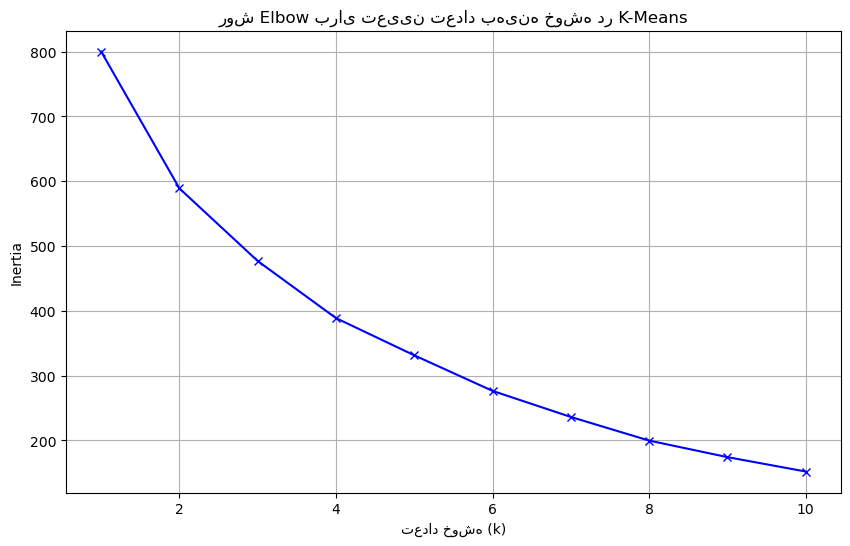


مراکز خوشه‌ها در K-Means (در مقیاس اصلی):
خوشه 0: Gender=0, Age=32.7, Income=87, Spending=82.1
خوشه 1: Gender=0, Age=36.5, Income=90, Spending=18.0
خوشه 2: Gender=-0, Age=49.8, Income=49, Spending=40.1
خوشه 3: Gender=0, Age=24.9, Income=40, Spending=61.2
خوشه 4: Gender=1, Age=55.7, Income=54, Spending=36.8


c:\Users\Legion\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


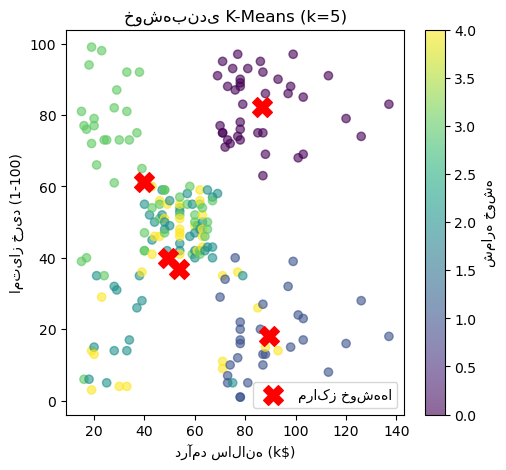

In [3]:
# تبدیل جنسیت به عدد
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])  # Female: 0, Male: 1

# انتخاب ویژگی‌های مورد نظر برای خوشه‌بندی
features = ['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values

# استانداردسازی
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- 1. خوشه‌بندی K-Means ---
print("\n" + "="*50)
print("خوشه‌بندی با K-Means")
print("="*50)

# پیدا کردن تعداد خوشه بهینه با روش Elbow
inertias = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# رسم نمودار Elbow
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertias, 'bx-')
plt.xlabel('تعداد خوشه (k)')
plt.ylabel('Inertia')
plt.title('روش Elbow برای تعیین تعداد بهینه خوشه در K-Means')
plt.grid(True)
plt.show()

# انتخاب k = 5 (طبق نمودار)
k_optimal = 5
kmeans = KMeans(n_clusters=k_optimal, init='k-means++', n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

# افزودن برچسب‌ها به DataFrame اصلی
df['KMeans_Cluster'] = kmeans_labels

# محاسبه مراکز خوشه‌ها در مقیاس اصلی (برای تفسیر بهتر)
cluster_centers_original = scaler.inverse_transform(kmeans.cluster_centers_)

print("\nمراکز خوشه‌ها در K-Means (در مقیاس اصلی):")
for i, center in enumerate(cluster_centers_original):
    print(f"خوشه {i}: Gender={center[0]:.0f}, Age={center[1]:.1f}, Income={center[2]:.0f}, Spending={center[3]:.1f}")

# نمودار K-Means بر اساس درآمد و امتیاز خرید
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
scatter = plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], 
                      c=kmeans_labels, cmap='viridis', alpha=0.6)
plt.scatter(cluster_centers_original[:, 2], cluster_centers_original[:, 3], 
            s=200, c='red', marker='X', label='مراکز خوشه‌ها')
plt.xlabel('درآمد سالانه (k$)')
plt.ylabel('امتیاز خرید (1-100)')
plt.title(f'خوشه‌بندی K-Means (k={k_optimal})')
plt.colorbar(scatter, label='شماره خوشه')
plt.legend()


خوشه‌بندی با DBSCAN
تعداد خوشه‌ها: 9
تعداد نقاط نویز (Noise): 105


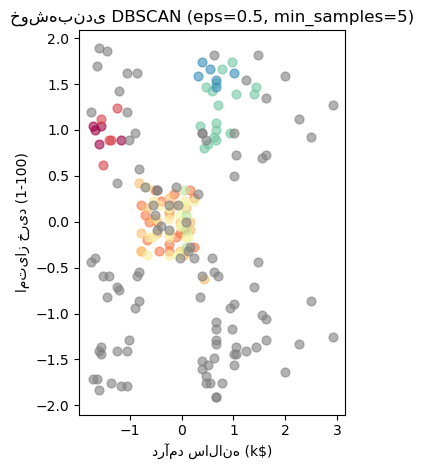

In [4]:
# --- 2. خوشه‌بندی DBSCAN ---
print("\n" + "="*50)
print("خوشه‌بندی با DBSCAN")
print("="*50)

eps = 0.5          # کاهش eps برای خوشه‌بندی دقیق‌تر
min_samples = 5
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_scaled)

df['DBSCAN_Cluster'] = dbscan_labels

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_db = list(dbscan_labels).count(-1)
print(f"تعداد خوشه‌ها: {n_clusters_db}")
print(f"تعداد نقاط نویز (Noise): {n_noise_db}")

# نمودار DBSCAN بر اساس درآمد و امتیاز خرید
plt.subplot(1, 2, 2)
unique_labels = set(dbscan_labels)
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = 'gray'  # نقاط نویز به رنگ خاکستری
    
    class_member_mask = (dbscan_labels == k)
    xy = X_scaled[class_member_mask]
    plt.scatter(xy[:, 2], xy[:, 3], s=40, c=[col], marker='o', alpha=0.6)

plt.xlabel('درآمد سالانه (k$)')
plt.ylabel('امتیاز خرید (1-100)')
plt.title(f'خوشه‌بندی DBSCAN (eps={eps}, min_samples={min_samples})')
plt.tight_layout()
plt.show()


خوشه‌بندی سلسله‌مراتبی


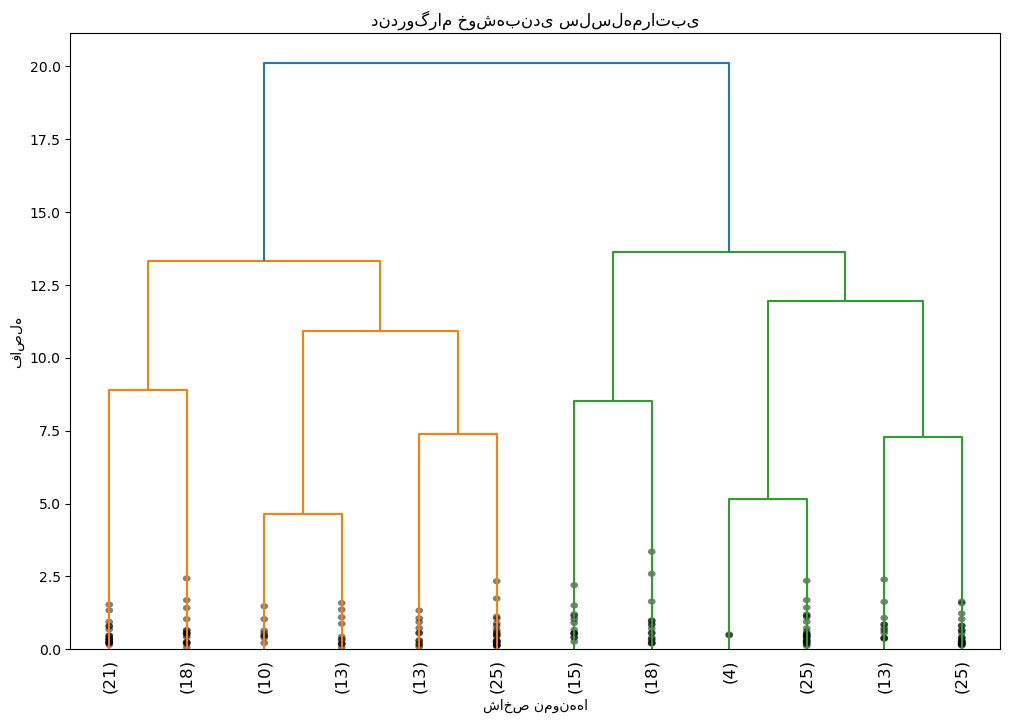

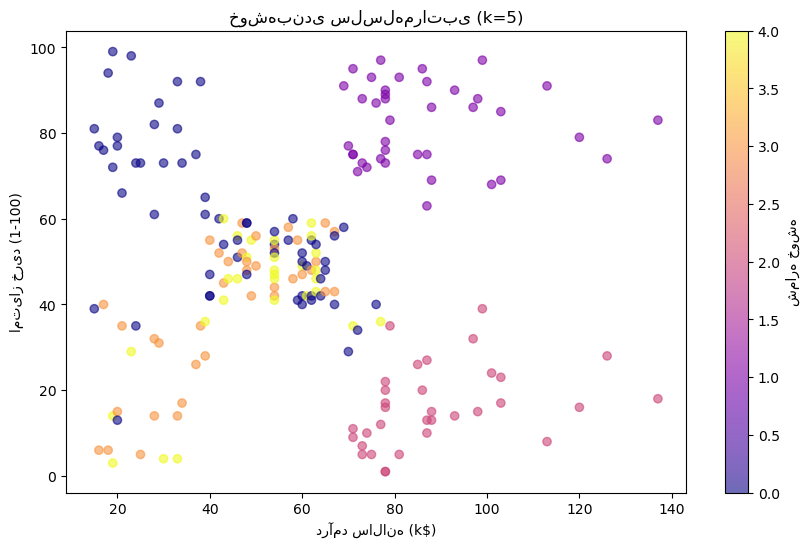


خلاصه نتایج خوشه‌بندی

میانگین ویژگی‌ها در خوشه‌های K-Means:
                Gender    Age  Annual Income (k$)  Spending Score (1-100)  \
KMeans_Cluster                                                              
0                 0.46  32.69               86.54                   82.13   
1                 0.45  36.48               89.52                   18.00   
2                 0.00  49.81               49.23                   40.07   
3                 0.41  24.91               39.72                   61.20   
4                 1.00  55.71               53.69                   36.77   

                Spending Score (1-100)  
KMeans_Cluster                          
0                                82.13  
1                                18.00  
2                                40.07  
3                                61.20  
4                                36.77  

تعداد نقاط در هر خوشه DBSCAN (شامل نویز):
DBSCAN_Cluster
-1    105
 0      5
 1      5
 2     18
 3     18
 4 

In [5]:

# --- 3. خوشه‌بندی سلسله‌مراتبی ---
print("\n" + "="*50)
print("خوشه‌بندی سلسله‌مراتبی")
print("="*50)

# محاسبه فاصله اقلیدسی بین نمونه‌ها و انجام پیوند (لینکاژ)
distance_matrix = pdist(X_scaled, metric='euclidean')
Z = linkage(distance_matrix, method='ward')

# رسم دندروگرام
plt.figure(figsize=(12, 8))
dendrogram(Z, truncate_mode='lastp', p=12, leaf_rotation=90., leaf_font_size=12., show_contracted=True)
plt.title('دندروگرام خوشه‌بندی سلسله‌مراتبی')
plt.xlabel('شاخص نمونه‌ها')
plt.ylabel('فاصله')
plt.show()

# انجام خوشه‌بندی با تعداد خوشه‌های 5 (طبق تحلیل دندروگرام)
n_clusters_hier = 5
hierarchical = AgglomerativeClustering(n_clusters=n_clusters_hier, linkage='ward')
hier_labels = hierarchical.fit_predict(X_scaled)

df['Hierarchical_Cluster'] = hier_labels

# نمودار سلسله‌مراتبی بر اساس درآمد و امتیاز خرید
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], 
                      c=hier_labels, cmap='plasma', alpha=0.6)
plt.xlabel('درآمد سالانه (k$)')
plt.ylabel('امتیاز خرید (1-100)')
plt.title(f'خوشه‌بندی سلسله‌مراتبی (k={n_clusters_hier})')
plt.colorbar(scatter, label='شماره خوشه')
plt.show()

# --- نمایش خلاصه نتایج ---
print("\n" + "="*50)
print("خلاصه نتایج خوشه‌بندی")
print("="*50)
print("\nمیانگین ویژگی‌ها در خوشه‌های K-Means:")
print(df.groupby('KMeans_Cluster')[features + ['Spending Score (1-100)']].mean().round(2))

print("\nتعداد نقاط در هر خوشه DBSCAN (شامل نویز):")
print(df['DBSCAN_Cluster'].value_counts().sort_index())

print("\nمیانگین ویژگی‌ها در خوشه‌های سلسله‌مراتبی:")
print(df.groupby('Hierarchical_Cluster')[features + ['Spending Score (1-100)']].mean().round(2))